In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
df_temp = pd.read_csv('../Part1_analysis/target_temp_EE_quadr_moanom.csv')
df_temp_terc = pd.read_csv('../Part1_analysis/eastern_temperature_terc_cat_new.csv')

In [3]:
df_nao = pd.read_csv('../Part1_analysis/NAO_week3.csv')

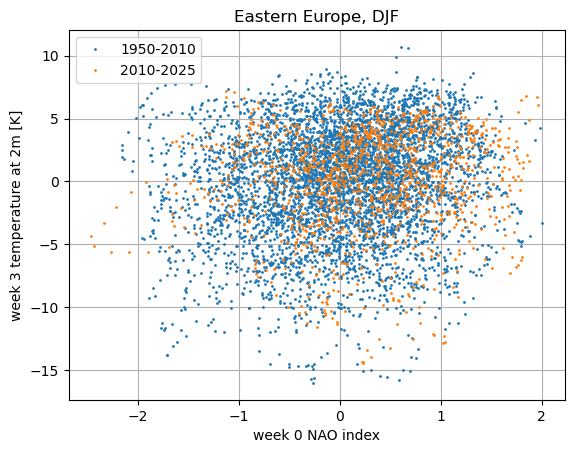

In [4]:
plt.plot(df_nao['nao_index'][:5040], df_temp['t2m'][:5040], 'o', markersize=1, label='1950-2010')
plt.plot(df_nao['nao_index'][5040:], df_temp['t2m'][5040:], 'o', markersize=1, label='2010-2025')
plt.xlabel('week 0 NAO index')
plt.ylabel('week 3 temperature at 2m [K]')
plt.title('Eastern Europe, DJF')
plt.legend()
plt.grid()

In [4]:
low_temp_train = df_nao[:5040][df_temp_terc[:5040]['tercile_category']==0]['nao_index']
medium_temp_train = df_nao[:5040][df_temp_terc[:5040]['tercile_category']==1]['nao_index']
high_temp_train = df_nao[:5040][df_temp_terc[:5040]['tercile_category']==2]['nao_index']

low_temp_test = df_nao[5040:][df_temp_terc[5040:]['tercile_category']==0]['nao_index']
medium_temp_test = df_nao[5040:][df_temp_terc[5040:]['tercile_category']==1]['nao_index']
high_temp_test = df_nao[5040:][df_temp_terc[5040:]['tercile_category']==2]['nao_index']

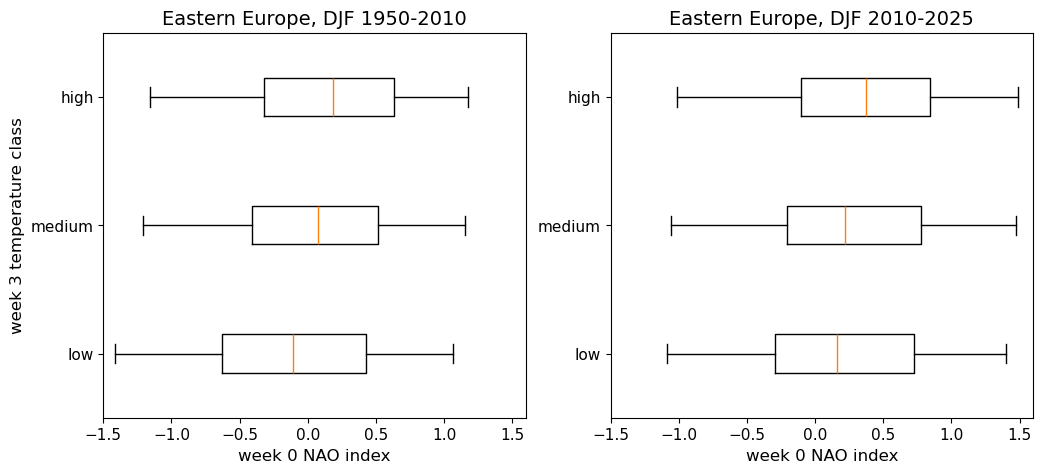

In [5]:
fig, ax = plt.subplots(1,2,figsize=(12,5))

ax[0].boxplot([low_temp_train, medium_temp_train, high_temp_train], orientation='horizontal', whis=[5,95], sym="", tick_labels=['low', 'medium', 'high'])
ax[0].set_xlabel('week 0 NAO index',fontsize=12)
ax[0].set_ylabel('week 3 temperature class',fontsize=12)
ax[0].set_title('Eastern Europe, DJF 1950-2010',fontsize=14)
ax[0].set_xlim((-1.5,1.6))
ax[0].tick_params(labelsize=11)

ax[1].boxplot([low_temp_test, medium_temp_test, high_temp_test], orientation='horizontal', whis=[5,95], sym="", tick_labels=['low', 'medium', 'high'])
ax[1].set_xlabel('week 0 NAO index',fontsize=12)
ax[1].set_title('Eastern Europe, DJF 2010-2025',fontsize=14)
ax[1].set_xlim((-1.5,1.6))
ax[1].tick_params(labelsize=11)

plt.savefig('EE_temp_nao_box.pdf', bbox_inches='tight')